# NYC Taxi Trips Analysis (March 2019)
**Author:** Manish  
**Tools:** Python, Pandas, Matplotlib, Seaborn  
**Data:** 6,433 Yellow and Green taxi trips in New York City

## Business Questions
1. Which hours and days are the busiest and most profitable?
2. Which boroughs and zones generate the most trips and revenue?
3. How do customers pay, and how much do card-paying customers tip?
4. How do Yellow and Green taxis differ in fare, distance and tips?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [2]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/taxis.csv"
df = pd.read_csv(url)

In [3]:
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [4]:
df.shape

(6433, 14)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   pickup           6433 non-null   str    
 1   dropoff          6433 non-null   str    
 2   passengers       6433 non-null   int64  
 3   distance         6433 non-null   float64
 4   fare             6433 non-null   float64
 5   tip              6433 non-null   float64
 6   tolls            6433 non-null   float64
 7   total            6433 non-null   float64
 8   color            6433 non-null   str    
 9   payment          6389 non-null   str    
 10  pickup_zone      6407 non-null   str    
 11  dropoff_zone     6388 non-null   str    
 12  pickup_borough   6407 non-null   str    
 13  dropoff_borough  6388 non-null   str    
dtypes: float64(5), int64(1), str(8)
memory usage: 703.7 KB


In [6]:
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [7]:
df.describe()

,passengers,distance,fare,tip,tolls,total
count,6433.000000,6433.000000,6433.000000,6433.00000,6433.000000,6433.000000
mean,1.539251,3.024617,13.091073,1.97922,0.325273,18.517794
std,1.203768,3.827867,11.551804,2.44856,1.415267,13.815570
min,0.000000,0.000000,1.000000,0.00000,0.000000,1.300000
25%,1.000000,0.980000,6.500000,0.00000,0.000000,10.800000
50%,1.000000,1.640000,9.500000,1.70000,0.000000,14.160000
75%,2.000000,3.210000,15.000000,2.80000,0.000000,20.300000
max,6.000000,36.700000,150.000000,33.20000,24.020000,174.820000


## 1. Data Cleaning & Preparation

In [8]:
df["pickup"] = pd.to_datetime(df["pickup"])
df["dropoff"] = pd.to_datetime(df["dropoff"])
df[["pickup", "dropoff"]].dtypes

pickup     datetime64[us]
dropoff    datetime64[us]
dtype: object

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
(df["passengers"] == 0).sum()

np.int64(96)

In [11]:
(df["distance"] == 0).sum()

np.int64(51)

In [12]:
df[df["distance"] == 0].head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
42,2019-03-30 23:59:14,2019-03-30 23:59:17,1,0.0,80.0,20.08,0.0,100.38,yellow,credit card,NaN,NaN,NaN,NaN
120,2019-03-21 17:21:44,2019-03-21 17:21:49,1,0.0,2.5,0.00,0.0,4.30,yellow,cash,JFK Airport,JFK Airport,Queens,Queens
622,2019-03-12 19:52:36,2019-03-12 19:52:55,3,0.0,120.0,33.20,12.5,166.00,yellow,credit card,NaN,NaN,NaN,NaN
670,2019-03-08 04:50:48,2019-03-08 04:51:07,1,0.0,2.5,0.00,0.0,6.30,yellow,cash,Lenox Hill East,Lenox Hill East,Manhattan,Manhattan
970,2019-03-29 00:02:00,2019-03-29 00:02:05,2,0.0,45.0,5.00,0.0,50.30,yellow,credit card,NaN,NaN,NaN,NaN


In [13]:
df["duration_min"] = ((df["dropoff"] - df["pickup"]).dt.total_seconds() / 60).round(1)
df["duration_min"].describe()

count    6433.000000
mean       14.349091
std        11.644096
min         0.000000
25%         6.500000
50%        10.900000
75%        18.500000
max       107.700000
Name: duration_min, dtype: float64

In [14]:
(df["duration_min"] <= 0).sum()

np.int64(12)

In [15]:
df[df["payment"].isnull()]["tip"].describe()

count    44.0
mean      0.0
std       0.0
min       0.0
25%       0.0
50%       0.0
75%       0.0
max       0.0
Name: tip, dtype: float64

In [16]:
text_cols = ["payment", "pickup_zone", "dropoff_zone", "pickup_borough", "dropoff_borough"]
df[text_cols] = df[text_cols].fillna("Unknown")
df.isnull().sum()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
duration_min       0
dtype: int64

In [17]:
df.groupby("payment")["tip"].agg(["count", "mean", "max"]).round(2)

,count,mean,max
payment,,,
Unknown,44,0.00,0.0
cash,1812,0.00,0.0
credit card,4577,2.78,33.2


In [18]:
df_clean = df[(df["distance"] > 0) & (df["duration_min"] > 0) & (df["pickup"].dt.month == 3)].copy()
print("Rows before:", len(df))
print("Rows after:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

Rows before: 6433
Rows after: 6380
Rows removed: 53


## 2. Feature Engineering & Outliers

In [19]:
df_clean["hour"] = df_clean["pickup"].dt.hour
df_clean["day_name"] = df_clean["pickup"].dt.day_name()
df_clean["is_weekend"] = df_clean["day_name"].isin(["Saturday", "Sunday"])

In [20]:
df_clean["time_of_day"] = pd.cut(
    df_clean["hour"],
    bins=[-1, 5, 11, 16, 20, 23],
    labels=["Night (0-5)", "Morning (6-11)", "Afternoon (12-16)", "Evening (17-20)", "Late Evening (21-23)"]
)

In [21]:
df_clean["tip_pct"] = (df_clean["tip"] / df_clean["fare"] * 100).round(1)
card = df_clean[df_clean["payment"] == "credit card"].copy()
card["tip_pct"].describe()

count    4553.000000
mean       23.855458
std        11.629208
min         0.000000
25%        18.200000
50%        25.600000
75%        30.700000
max        93.300000
Name: tip_pct, dtype: float64

In [22]:
df_clean["speed_mph"] = (df_clean["distance"] / (df_clean["duration_min"] / 60)).round(1)
df_clean["speed_mph"].describe()

count    6380.000000
mean       13.203386
std        76.907688
min         1.200000
25%         7.600000
50%        10.100000
75%        13.700000
max      5640.000000
Name: speed_mph, dtype: float64

In [23]:
p25 = df_clean["fare"].quantile(0.25)
p75 = df_clean["fare"].quantile(0.75)
iqr = p75 - p25
upper = p75 + 1.5 * iqr
print("Upper limit:", upper)
print("Trips above it:", (df_clean["fare"] > upper).sum())

Upper limit: 27.75
Trips above it: 579


In [24]:
cols = ["pickup_borough", "dropoff_borough", "distance", "duration_min", "fare", "total"]
df_clean.nlargest(10, "fare")[cols]

,pickup_borough,dropoff_borough,distance,duration_min,fare,total
5364,Queens,Queens,36.70,64.8,150.00,174.82
5648,Queens,Unknown,33.46,89.9,150.00,169.70
4050,Queens,Unknown,33.76,56.0,143.50,144.30
2231,Manhattan,Unknown,26.35,46.4,130.00,136.56
4815,Manhattan,Unknown,10.36,25.4,100.00,123.36
4219,Queens,Unknown,36.66,62.1,96.50,113.56
5567,Brooklyn,Queens,25.51,94.0,93.50,94.80
3500,Queens,Unknown,24.63,69.8,87.50,107.16
5827,Brooklyn,Manhattan,20.64,69.4,86.14,92.40
2402,Queens,Unknown,19.20,24.8,84.00,85.30


In [25]:
(df_clean["speed_mph"] > 80).sum()

np.int64(10)

In [26]:
df_clean[df_clean["speed_mph"] > 80][["distance", "duration_min", "speed_mph", "fare"]]

,distance,duration_min,speed_mph,fare
400,0.90,0.1,540.0,2.50
491,1.60,0.1,960.0,2.50
770,9.40,0.1,5640.0,2.50
2387,1.80,0.6,180.0,69.06
3336,1.70,0.3,340.0,14.00
3571,0.81,0.2,243.0,66.00
4746,1.30,0.2,390.0,2.50
5284,1.70,0.2,510.0,2.50
6089,10.10,0.3,2020.0,12.00
6169,4.10,1.0,246.0,3.00


In [27]:
(df_clean["payment"].value_counts(normalize=True) * 100).round(1)

payment
credit card    71.4
cash           28.0
Unknown         0.6
Name: proportion, dtype: float64

In [28]:
df_clean[["pickup", "hour", "day_name", "time_of_day", "is_weekend", "duration_min", "tip_pct", "speed_mph"]].head()

,pickup,hour,day_name,time_of_day,is_weekend,duration_min,tip_pct,speed_mph
0,2019-03-23 20:21:09,20,Saturday,Evening (17-20),True,6.2,30.7,15.5
1,2019-03-04 16:11:55,16,Monday,Afternoon (12-16),False,7.1,0.0,6.7
2,2019-03-27 17:53:01,17,Wednesday,Evening (17-20),False,7.4,31.5,11.1
3,2019-03-10 01:23:59,1,Sunday,Night (0-5),True,25.9,22.8,17.8
4,2019-03-30 13:27:42,13,Saturday,Afternoon (12-16),True,9.5,12.2,13.6


### Cleaning Decisions
Converted pickup and dropoff to datetime; no duplicate rows were found.

Removed 53 invalid or out-of-period trips (zero distance, zero duration, or from February). 

Some zero-distance trips lasted 3 seconds with fares up to $120.

Removed 10 trips with impossible speeds (above 80 mph, up to 5,640 mph) caused by durations under 1 minute.

Filled missing payment, zone and borough labels with "Unknown" (text only, no numbers were invented).

Kept 579 high-fare trips flagged by the IQR rule: they are long-distance trips (up to 37 miles, mostly from Queens) and represent real revenue.

Kept trips with 0 passengers because the fare is valid, but passenger counts are not used for conclusions.

Cash tips are always $0 because they are not recorded, so tips are analysed for card payments only.

In [29]:
df_clean = df_clean[df_clean["speed_mph"] <= 80].copy()
card = df_clean[df_clean["payment"] == "credit card"].copy()
df_clean.shape

(6370, 21)

## 3. Q1: Which Hours and Days Are the Busiest and Most Profitable?

In [30]:
hourly = df_clean.groupby("hour").agg(
    trips=("fare", "count"),
    fare_revenue=("fare", "sum"),
    avg_fare=("fare", "mean")
).round(1)
hourly.sort_values("trips", ascending=False).head(5)

,trips,fare_revenue,avg_fare
hour,,,
18,416,5083.8,12.2
19,405,4831.7,11.9
17,382,5148.4,13.5
20,364,4331.2,11.9
21,354,4621.9,13.1


In [31]:
print("Busiest hour:", hourly["trips"].idxmax())
print("Highest fare revenue hour:", hourly["fare_revenue"].idxmax())
print("Highest average fare hour:", hourly["avg_fare"].idxmax())

Busiest hour: 18
Highest fare revenue hour: 17
Highest average fare hour: 5


In [32]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df_clean["date"] = df_clean["pickup"].dt.date
days_count = df_clean.groupby("day_name")["date"].nunique()
days_count

day_name
Friday       5
Monday       4
Saturday     5
Sunday       5
Thursday     4
Tuesday      4
Wednesday    4
Name: date, dtype: int64

In [33]:
daily = df_clean.groupby("day_name").agg(
    trips=("fare", "count"),
    fare_revenue=("fare", "sum"),
    avg_fare=("fare", "mean")
).round(1).reindex(day_order)
daily["trips_per_day"] = (daily["trips"] / days_count).round(0)
daily["revenue_per_day"] = (daily["fare_revenue"] / days_count).round(0)
daily

,trips,fare_revenue,avg_fare,trips_per_day,revenue_per_day
day_name,,,,,
Monday,705,9464.6,13.4,176.0,2366.0
Tuesday,814,10688.3,13.1,204.0,2672.0
Wednesday,956,13030.8,13.6,239.0,3258.0
Thursday,898,11926.3,13.3,224.0,2982.0
Friday,1102,14296.9,13.0,220.0,2859.0
Saturday,1031,12792.9,12.4,206.0,2559.0
Sunday,864,10724.3,12.4,173.0,2145.0


In [34]:
tod = df_clean.groupby("time_of_day", observed=True).agg(
    trips=("fare", "count"),
    fare_revenue=("fare", "sum"),
    avg_fare=("fare", "mean")
).round(1)
tod["trip_share_pct"] = (tod["trips"] / tod["trips"].sum() * 100).round(1)
tod

,trips,fare_revenue,avg_fare,trip_share_pct
time_of_day,,,,
Night (0-5),586,7927.0,13.5,9.2
Morning (6-11),1601,20503.8,12.8,25.1
Afternoon (12-16),1654,22870.4,13.8,26.0
Evening (17-20),1567,19395.2,12.4,24.6
Late Evening (21-23),962,12227.7,12.7,15.1


In [35]:
pivot = df_clean.pivot_table(index="day_name", columns="hour", values="fare", aggfunc="count").reindex(day_order)
pivot = pivot.div(days_count, axis=0).round(1)

## Chart 1: trips by hour

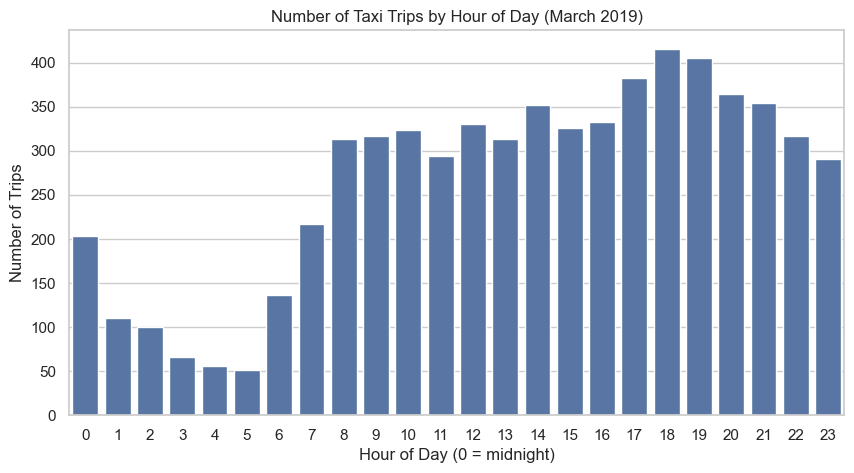

In [36]:
os.makedirs("images", exist_ok=True)
sns.set_theme(style="whitegrid")

hourly_plot = hourly.reset_index()
plt.figure(figsize=(10, 5))
sns.barplot(data=hourly_plot, x="hour", y="trips", color="#4C72B0")
plt.title("Number of Taxi Trips by Hour of Day (March 2019)")
plt.xlabel("Hour of Day (0 = midnight)")
plt.ylabel("Number of Trips")
plt.savefig("images/01_trips_by_hour.png", dpi=150, bbox_inches="tight")
plt.show()

## Chart 2: heatmap

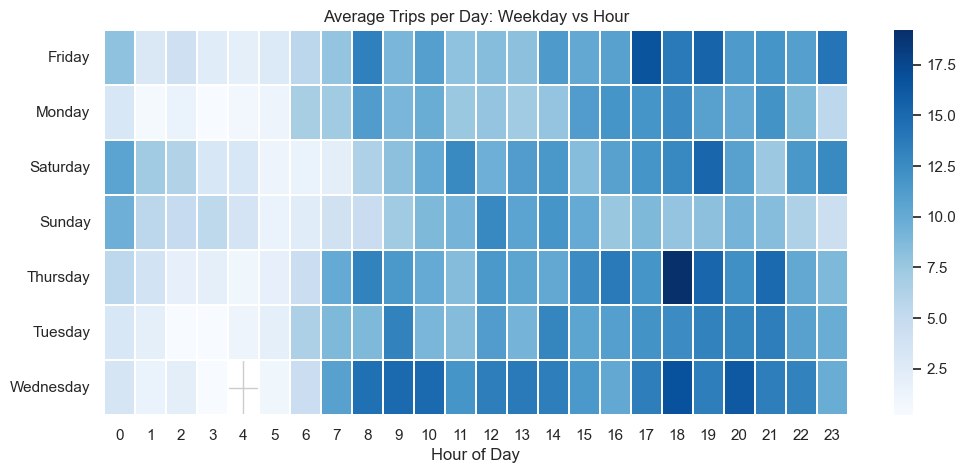

In [37]:
plt.figure(figsize=(12, 5))
sns.heatmap(pivot, cmap="Blues", linewidths=0.3)
plt.title("Average Trips per Day: Weekday vs Hour")
plt.xlabel("Hour of Day")
plt.ylabel("")
plt.savefig("images/02_heatmap_day_hour.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Q2: Which Boroughs and Zones Generate the Most Trips and Revenue?

In [38]:
borough = df_clean.groupby("pickup_borough").agg(
    trips=("fare", "count"),
    fare_revenue=("fare", "sum"),
    avg_fare=("fare", "mean"),
    avg_distance=("distance", "mean")
).round(1)
borough["revenue_share_pct"] = (borough["fare_revenue"] / borough["fare_revenue"].sum() * 100).round(1)
borough.sort_values("fare_revenue", ascending=False)

,trips,fare_revenue,avg_fare,avg_distance,revenue_share_pct
pickup_borough,,,,,
Manhattan,5248,58454.9,11.1,2.4,70.5
Queens,636,16094.5,25.3,7.7,19.4
Brooklyn,374,6154.5,16.5,4.2,7.4
Bronx,97,2005.2,20.7,5.8,2.4
Unknown,15,215.0,14.3,3.5,0.3


In [39]:
zones = df_clean.groupby("pickup_zone").agg(
    trips=("fare", "count"),
    fare_revenue=("fare", "sum"),
    avg_fare=("fare", "mean")
).round(1)
zones.sort_values("fare_revenue", ascending=False).head(10)

,trips,fare_revenue,avg_fare
pickup_zone,,,
JFK Airport,145,6568.0,45.3
LaGuardia Airport,146,4457.0,30.5
Midtown Center,229,2818.5,12.3
Penn Station/Madison Sq West,210,2460.0,11.7
Times Sq/Theatre District,183,2288.6,12.5
Midtown East,198,2177.0,11.0
Clinton East,207,2128.0,10.3
Union Sq,180,1984.0,11.0
Lincoln Square East,176,1952.5,11.1


In [40]:
zones[zones["trips"] >= 20].sort_values("avg_fare", ascending=False).head(5)

,trips,fare_revenue,avg_fare
pickup_zone,,,
JFK Airport,145,6568.0,45.3
LaGuardia Airport,146,4457.0,30.5
Financial District North,34,546.5,16.1
World Trade Center,24,385.5,16.1
Battery Park City,43,681.5,15.8


In [41]:
df_clean["dropoff_zone"].value_counts().head(10)

dropoff_zone
Upper East Side North           245
Murray Hill                     218
Midtown Center                  214
Midtown East                    176
Upper East Side South           176
Times Sq/Theatre District       159
Lincoln Square East             155
Clinton East                    150
East Village                    150
Penn Station/Madison Sq West    148
Name: count, dtype: int64

## Chart 3: borough revenue

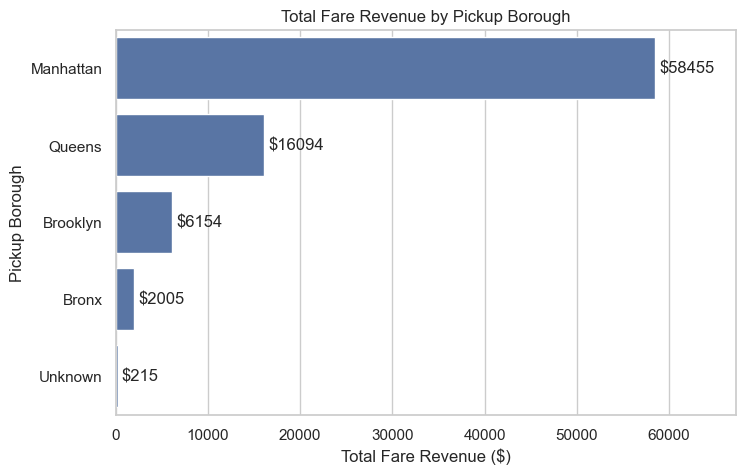

In [42]:
b_plot = borough.sort_values("fare_revenue", ascending=False).reset_index()
plt.figure(figsize=(8, 5))
ax = sns.barplot(data=b_plot, x="fare_revenue", y="pickup_borough", color="#4C72B0")
ax.bar_label(ax.containers[0], fmt="$%.0f", padding=3)
plt.xlim(0, b_plot["fare_revenue"].max() * 1.15)
plt.title("Total Fare Revenue by Pickup Borough")
plt.xlabel("Total Fare Revenue ($)")
plt.ylabel("Pickup Borough")
plt.savefig("images/03_revenue_by_borough.png", dpi=150, bbox_inches="tight")
plt.show()

## Chart 4: top 10 pickup zones

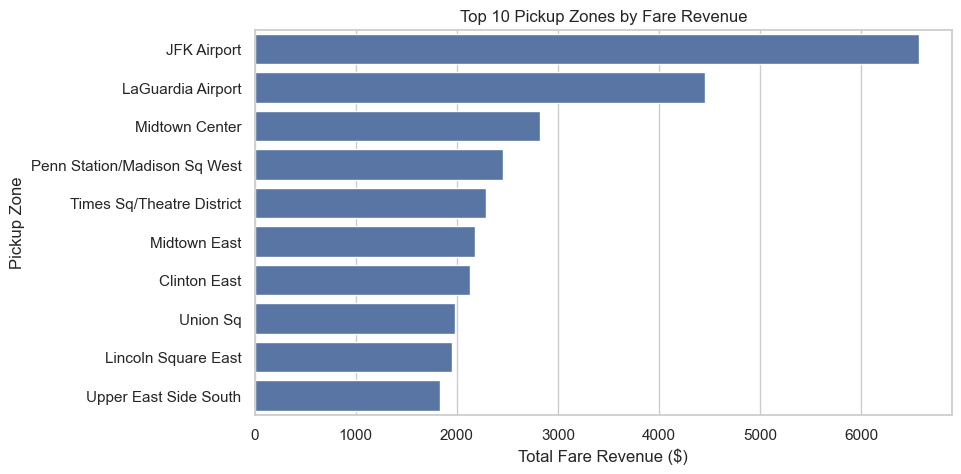

In [43]:
z_plot = zones.sort_values("fare_revenue", ascending=False).head(10).reset_index()
plt.figure(figsize=(9, 5))
sns.barplot(data=z_plot, x="fare_revenue", y="pickup_zone", color="#4C72B0")
plt.title("Top 10 Pickup Zones by Fare Revenue")
plt.xlabel("Total Fare Revenue ($)")
plt.ylabel("Pickup Zone")
plt.savefig("images/04_top_pickup_zones.png", dpi=150, bbox_inches="tight")
plt.show()

### Q1 Finding
**Busiest hour: 6 PM (416 trips).** The evening rush (5-8 PM) carries 24.6% of trips in just 4 hours.

**Highest fare revenue hour: 5 PM ($5,148)**  because its average fare ($13.5) is higher than at 6 PM ($12.2).

**Busiest day per day: Wednesday** (239 trips, $3,258 in fares), then Thursday and Friday. Friday has the most total trips only because March 2019 has five Fridays. 

**Sunday is the quietest** (173 trips per day).

**Limitations:** one month of data; revenue means meter fare only (no tips, tolls or surcharges).

### Q2 Finding
- **Manhattan dominates:** 82.4% of trips and 70.5% of fare revenue ($58,455), mostly short trips (average 2.4 miles, $11.1).
- **Queens has only 10.0% of trips but 19.4% of revenue,** because its average fare is $25.3.
- **JFK ($6,568) and LaGuardia ($4,457) are the top 2 revenue zones.** Together they are 4.6% of trips but 13.3% of revenue.
- **Top destinations:** Upper East Side North (245 trips), Murray Hill (218) and Midtown Center (214).
- **Limitations:** one month of data; 15 trips have an unknown pickup borough.

## 5. Q3: How Do Customers Pay, and How Much Do Card-Paying Customers Tip?

In [44]:
df_clean.groupby("payment")["fare"].agg(["count", "mean", "sum"]).round(1)

,count,mean,sum
payment,,,
Unknown,34,12.2,415.5
cash,1787,11.6,20802.0
credit card,4549,13.6,61706.6


In [45]:
card["tip_pct"].describe()

count    4549.000000
mean       23.866674
std        11.622323
min         0.000000
25%        18.200000
50%        25.600000
75%        30.700000
max        93.300000
Name: tip_pct, dtype: float64

In [46]:
card["no_tip"] = card["tip"] == 0
print("Card trips with no tip (%):", round(card["no_tip"].mean() * 100, 1))

Card trips with no tip (%): 9.7


In [47]:
card["fare_band"] = pd.cut(card["fare"], bins=[0, 8, 12, 20, 500], labels=["Up to $8", "$8-12", "$12-20", "Above $20"])
card.groupby("fare_band", observed=True)["tip_pct"].agg(["count", "mean", "median"]).round(1)

,count,mean,median
fare_band,,,
Up to $8,1826,28.8,30.1
$8-12,1095,23.9,26.5
$12-20,884,20.2,24.2
Above $20,744,16.1,21.0


In [48]:
card["dist_band"] = pd.cut(card["distance"], bins=[0, 1, 2, 5, 50], labels=["Up to 1 mi", "1-2 mi", "2-5 mi", "Above 5 mi"])
card.groupby("dist_band", observed=True)["tip_pct"].agg(["count", "mean", "median"]).round(1)

,count,mean,median
dist_band,,,
Up to 1 mi,1121,30.1,31.8
1-2 mi,1445,25.2,27.5
2-5 mi,1222,21.3,24.6
Above 5 mi,761,16.3,21.2


In [49]:
card.groupby("time_of_day", observed=True)["tip_pct"].agg(["count", "mean", "median"]).round(1)

,count,mean,median
time_of_day,,,
Night (0-5),388,24.5,25.6
Morning (6-11),1161,22.3,25.0
Afternoon (12-16),1147,23.0,25.3
Evening (17-20),1142,25.1,26.3
Late Evening (21-23),711,25.5,26.3


In [50]:
card.groupby("is_weekend")["tip_pct"].agg(["count", "mean", "median"]).round(1)

,count,mean,median
is_weekend,,,
False,3251,23.8,25.7
True,1298,23.9,25.4


## Chart 5: payment mix

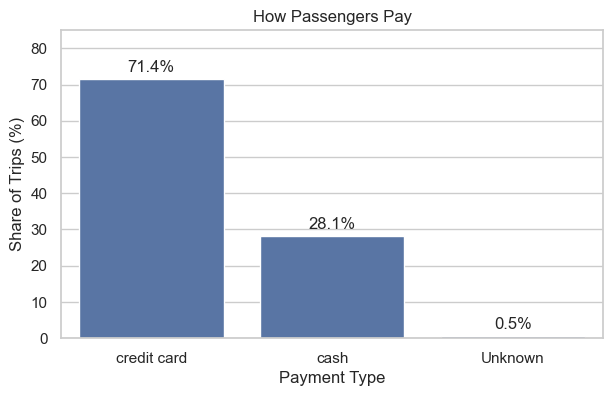

In [51]:
os.makedirs("images", exist_ok=True)
sns.set_theme(style="whitegrid")

pay_pct = (df_clean["payment"].value_counts(normalize=True) * 100).round(1).reset_index()
pay_pct.columns = ["payment", "share_pct"]

plt.figure(figsize=(7, 4))
ax = sns.barplot(data=pay_pct, x="payment", y="share_pct", color="#4C72B0")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
plt.ylim(0, 85)
plt.title("How Passengers Pay")
plt.xlabel("Payment Type")
plt.ylabel("Share of Trips (%)")
plt.savefig("images/05_payment_mix.png", dpi=150, bbox_inches="tight")
plt.show()

## Chart 6: tip % by distance

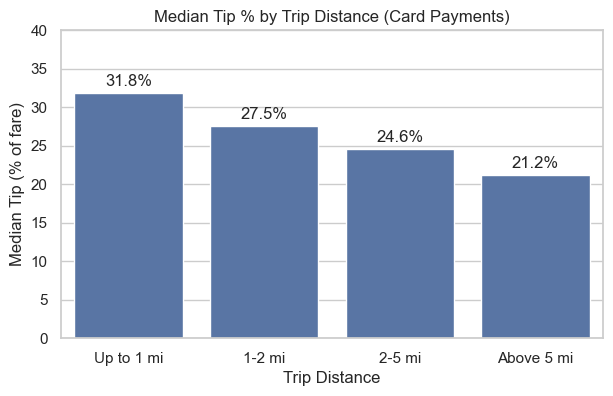

In [52]:
d_plot = card.groupby("dist_band", observed=True)["tip_pct"].median().reset_index()

plt.figure(figsize=(7, 4))
ax = sns.barplot(data=d_plot, x="dist_band", y="tip_pct", color="#4C72B0")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
plt.ylim(0, 40)
plt.title("Median Tip % by Trip Distance (Card Payments)")
plt.xlabel("Trip Distance")
plt.ylabel("Median Tip (% of fare)")
plt.savefig("images/06_tip_by_distance.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Q4: How Do Yellow and Green Taxis Differ in Fare, Distance and Tips?

In [53]:
df_clean.groupby("color").agg(
    trips=("fare", "count"),
    avg_fare=("fare", "mean"),
    median_fare=("fare", "median"),
    avg_distance=("distance", "mean"),
    avg_duration=("duration_min", "mean"),
    fare_revenue=("fare", "sum")
).round(2)

,trips,avg_fare,median_fare,avg_distance,avg_duration,fare_revenue
color,,,,,,
green,956,14.13,9.5,3.48,15.95,13508.95
yellow,5414,12.82,9.5,2.97,14.21,69415.16


In [54]:
(pd.crosstab(df_clean["color"], df_clean["pickup_borough"], normalize="index") * 100).round(1)

pickup_borough,Bronx,Brooklyn,Manhattan,Queens,Unknown
color,,,,,
green,8.5,31.9,30.6,29.0,0.0
yellow,0.3,1.3,91.5,6.6,0.3


In [55]:
known = df_clean[df_clean["pickup_borough"] != "Unknown"]
known.groupby(["pickup_borough", "color"]).agg(
    trips=("fare", "count"),
    avg_fare=("fare", "mean"),
    avg_distance=("distance", "mean")
).round(1)

trips  avg_fare  avg_distance
pickup_borough color                                
Bronx          green      81      20.1           5.7
               yellow     16      23.7           6.7
Brooklyn       green     305      16.1           4.0
               yellow     69      17.9           4.7
Manhattan      green     293      10.6           2.3
               yellow   4955      11.2           2.4
Queens         green     277      13.9           3.5
               yellow    359      34.1          10.9

In [56]:
(pd.crosstab(df_clean["color"], df_clean["payment"], normalize="index") * 100).round(1)

payment,Unknown,cash,credit card
color,,,
green,0.4,40.5,59.1
yellow,0.6,25.9,73.6


In [57]:
card.groupby("color").agg(
    card_trips=("tip_pct", "count"),
    avg_tip_pct=("tip_pct", "mean"),
    median_tip_pct=("tip_pct", "median"),
    no_tip_share=("no_tip", "mean")
).assign(no_tip_share=lambda t: (t["no_tip_share"] * 100).round(1)).round(1)

,card_trips,avg_tip_pct,median_tip_pct,no_tip_share
color,,,,
green,565,12.9,11.8,45.8
yellow,3984,25.4,26.3,4.6


## Chart 7: no-tip share by colour

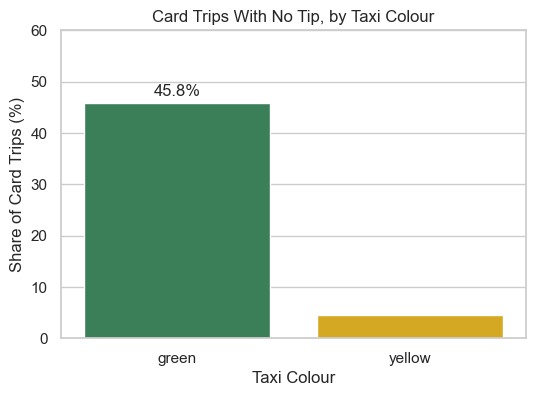

In [58]:
nt = (card.groupby("color")["no_tip"].mean() * 100).round(1).reset_index()
nt.columns = ["color", "no_tip_pct"]
palette = {"yellow": "#F2B705", "green": "#2E8B57"}

plt.figure(figsize=(6, 4))
ax = sns.barplot(data=nt, x="color", y="no_tip_pct", hue="color", palette=palette, legend=False)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
plt.ylim(0, 60)
plt.title("Card Trips With No Tip, by Taxi Colour")
plt.xlabel("Taxi Colour")
plt.ylabel("Share of Card Trips (%)")
plt.savefig("images/07_no_tip_by_colour.png", dpi=150, bbox_inches="tight")
plt.show()

## Chart 8: fare by borough and colour

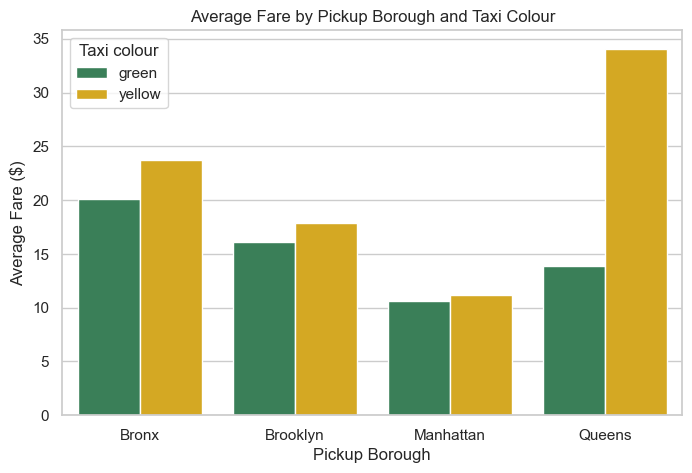

In [59]:
bc = known.groupby(["pickup_borough", "color"])["fare"].mean().round(1).reset_index()

plt.figure(figsize=(8, 5))
sns.barplot(data=bc, x="pickup_borough", y="fare", hue="color", palette=palette)
plt.title("Average Fare by Pickup Borough and Taxi Colour")
plt.xlabel("Pickup Borough")
plt.ylabel("Average Fare ($)")
plt.legend(title="Taxi colour")
plt.savefig("images/08_fare_by_borough_colour.png", dpi=150, bbox_inches="tight")
plt.show()

### Q3 Finding
- **Card is the main payment method:** 71.4% of trips (cash 28.1%, unknown 0.5%), and card trips have a higher average fare ($13.6 vs $11.6 for cash).
- **Card riders tip 23.9% of the fare on average (median 25.6%),** and only 9.7% of card trips have no tip.
- **Tip % falls as trips get longer and costlier:** the median is 31.8% for trips up to 1 mile versus 21.2% for trips above 5 miles. Time of day and weekday vs weekend make little difference (median 25.0%-26.3%).
- **Limitations:** cash tips are not recorded (always $0), so tips are analysed for card payments only; tip % is calculated on the meter fare, not the total bill.

### Q4 Finding
- **Yellow taxis make 85.0% of trips (5,414) and $69,415 in fares; green taxis make 956 trips and $13,509.** Median fare is the same ($9.5).
- **They work in different places:** 91.5% of yellow trips start in Manhattan, while green trips are spread across Brooklyn (31.9%), Manhattan (30.6%), Queens (29.0%) and the Bronx (8.5%).
- **Within the same borough, fares are similar** (Manhattan: yellow $11.2, green $10.6). Yellow's higher Queens average ($34.1 vs $13.9) comes from much longer trips (10.9 vs 3.5 miles), consistent with the airport trips seen in Q2.
- **Green taxi riders tip far less:** on card trips the average tip is 12.9% for green versus 25.4% for yellow, and 45.8% of green card trips have no tip (yellow: 4.6%). Green riders also pay cash more often (40.5% vs 25.9%).
- **Limitations:** only 565 green card trips; the data cannot explain why green tips are lower.

## 7. Key Findings
1. **Peak demand:** 6 PM is the busiest hour and 5 PM brings the most fare revenue. Wednesday is the busiest day per day and Sunday the quietest.
2. **Where the money is:** Manhattan has 82.4% of trips and 70.5% of revenue. Queens has 10.0% of trips but 19.4% of revenue, and JFK plus LaGuardia generate 13.3% of revenue from just 4.6% of trips.
3. **Payments and tips:** 71.4% of trips are paid by card, and card riders tip 23.9% on average. Tip % drops on longer trips.
4. **Yellow vs green:** yellow taxis serve Manhattan, green taxis serve the outer boroughs. Green card riders tip about half as much as yellow riders (12.9% vs 25.4%).

## 8. Limitations
- One month of data (March 2019) and 6,370 trips after cleaning.
- Revenue means the meter fare only; tips, tolls and surcharges are excluded.
- Cash tips are not recorded, so tip analysis covers card payments only.
- 53 invalid trips and 10 trips with impossible speeds were removed.

## 9. Recommendations
- Put more cabs in Manhattan during the 5-8 PM rush.
- Airport trips are worth 2-4 times a typical Manhattan fare (JFK $45.3, LaGuardia $30.5 vs $11.1), so keep airport coverage strong.
- Never compare tips across payment types without checking how tips are recorded.
- Follow-up: compare other months, and investigate why green-taxi tips are lower.